# Incentive to Win

What one more win is worth to a team in draft value, under the lottery its season feeds.

| Lottery | Seasons | Teams | Drawn | Odds |
|---|---|---|---|---|
| 2015-2018 | 2014-15 to 2017-18 | 14 non-playoff | Picks 1-3 | 25% for the worst record down to 0.5% |
| 2019-2026 | 2018-19 to 2025-26 | 14 non-playoff (play-in losers from 2021) | Picks 1-4 | 14% for each of the three worst records down to 0.5% |
| 3-2-1 | 2026-27 on | 16: the 10 non-play-in teams, the four 9 and 10 seeds, the two 7-vs-8 losers | All 16 | Lottery balls: 3 for non-play-in teams, 2 for the 9 and 10 seeds, 1 for the 7-vs-8 losers. The three worst records lose a ball ('draft relegated') but fall no lower than 12th. A team's original pick can't be 1st in consecutive drafts or top five in three consecutive drafts |

Picks after the lottery go by record. Ties in record are broken at random.

**Pick value:** the VORP of the drafted player over the four seasons after the draft (zero for players who never played), averaged by slot over the 1995-2022 drafts and smoothed with value = a·exp(-b·(pick - 1)) + c.

**Season simulation:** from a date, every remaining game is simulated from frozen ratings: Elo and full-roster talent ([09_game_outcomes](09_game_outcomes.ipynb)) combined by a logistic fit on earlier seasons. Each simulated season adds a random shock to every team's win logit (SD 0.35, set so the spread of actual final wins around the simulated mean matches the simulated spread). Then the play-in and the lottery are simulated. 2,000 simulations for the history, 8,000 for the current season.

**Incentives:** a team's draft value is the expected value of the first-round picks it owns. The draft incentive is its draft value if it wins its next game minus its draft value if it loses it; the playoff incentive is the same for its chance of making the playoffs (top six or through the play-in). Both runs share every other random draw.

**History:** weekly from January 1, 2014-15 to 2025-26 (2019-20 excluded: its lottery used the standings frozen when the season was suspended), assuming every team owns its own pick. The same seasons are also replayed under the 3-2-1 lottery.

**2027 pick ownership:** each trade's terms as listed by SalarySwish (salaryswish.com/draft/2027), checked against Tankathon's resolved 2027 draft order on 2026-10-23. Lottery rules: NBA, 2026-05-28 (pr.nba.com); base odds checked against Tankathon's 3-2-1 odds table.

Source: Basketball-Reference (draft classes, player and team seasons, game logs, 2026-27 schedule and box scores).

In [1]:
import numpy as np
import pandas as pd
import plotly.io as pio

from nba_analytics.teams import games, incentive, lottery, picks
from nba_analytics.teams.incentive_plots import (incentive_by_rank, plot_current,
                                                 plot_holdings, plot_incentive_by_rank,
                                                 plot_lottery_odds, plot_pick_value,
                                                 plot_residuals, plot_value_by_rank)

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7
pd.set_option("display.max_rows", 100)

FIRST, LAST = 2015, 2026
TODAY = "2026-10-23"
SYSTEMS = {"2015-2018": lottery.RULES_2015, "2019-2026": lottery.RULES_2019,
           "3-2-1": lottery.RULES_2027}

## Lottery odds

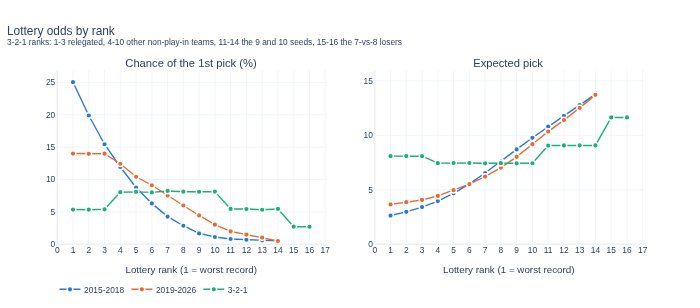

In [2]:
odds = {name: lottery.base_odds(rules) for name, rules in SYSTEMS.items()}
plot_lottery_odds(odds).show()

## Pick value

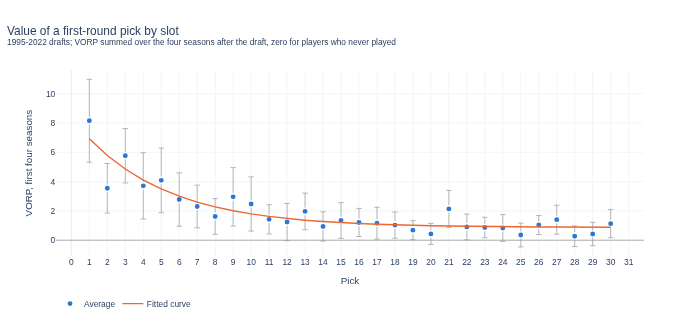

In [3]:
outcomes = picks.draft_outcomes()
coef = picks.fit_pick_value(outcomes)
plot_pick_value(outcomes, picks.pick_value(np.arange(1, 31), coef)).show()

In [4]:
slots = [1, 2, 3, 4, 5, 8, 10, 12, 14, 16, 20, 25, 30]
pd.DataFrame({"pick": slots, "fitted VORP": picks.pick_value(np.array(slots), coef).round(2),
              "average VORP": outcomes.groupby("pick")["vorp"].mean().loc[slots].round(2).values}
             ).set_index("pick").T

pick,1,2,3,4,5,8,10,12,14,16,20,25,30
fitted VORP,6.92,5.78,4.86,4.11,3.50,2.28,1.80,1.48,1.28,1.14,0.99,0.91,0.89
average VORP,8.15,3.55,5.76,3.71,4.09,1.62,2.48,1.24,0.94,1.21,0.43,0.36,1.13


## Expected pick value by lottery rank

A team's own pick, before the lottery.

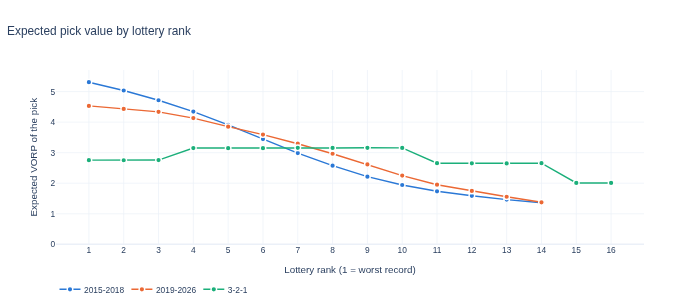

In [5]:
values = {name: o @ picks.pick_value(np.arange(1, o.shape[1] + 1), coef)
          for name, o in odds.items()}
plot_value_by_rank(values).show()

## Season simulation spread

Actual final wins minus the simulated mean, divided by the simulated SD, for all 30 teams in 10 seasons (2019-20 and 2020-21 excluded). An SD of 1 matches reality.

In [6]:
df = games.game_dataset(FIRST - 1, LAST)
seasons = [s for s in range(FIRST, LAST + 1) if s not in (2020, 2021)]
spread = pd.concat([incentive.calibration(df, seasons, [0.15, 0.25, 0.35, 0.45], md)
                    .assign(date=md) for md in ["11-15", "01-15", "03-01"]])
spread.pivot(index="strength_sd", columns="date", values="z_sd")[["11-15", "01-15", "03-01"]] \
    .round(3)

date,11-15,01-15,03-01
strength_sd,,,
0.15,1.538,1.403,1.148
0.25,1.281,1.237,1.069
0.35,1.071,1.081,0.983
0.45,0.916,0.951,0.898


## Draft incentive by projected record

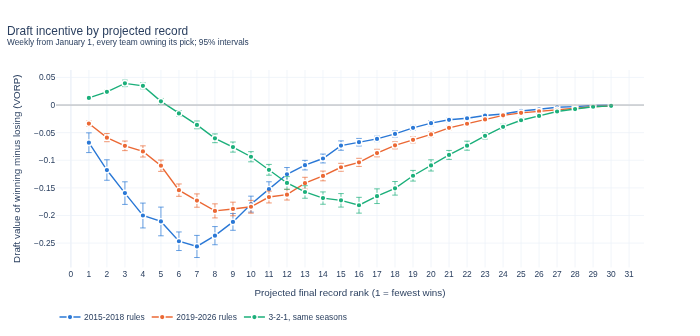

In [7]:
replay = incentive.replay(FIRST, LAST)
replay_321 = incentive.replay(FIRST, LAST, rules=incentive.THREE_TWO_ONE)
curves = {"2015-2018 rules": incentive_by_rank(replay[replay["season"] <= 2018]),
          "2019-2026 rules": incentive_by_rank(replay[replay["season"] >= 2019]),
          "3-2-1, same seasons": incentive_by_rank(replay_321)}
plot_incentive_by_rank(curves).show()

In [8]:
pd.DataFrame({name: c["mean"] for name, c in curves.items()}).round(3).T

rank,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,29.0,30.0
2015-2018 rules,-0.068,-0.118,-0.159,-0.200,-0.211,-0.247,-0.256,-0.236,-0.212,-0.179,...,-0.027,-0.024,-0.019,-0.016,-0.011,-0.008,-0.004,-0.003,-0.001,-0.000
2019-2026 rules,-0.034,-0.059,-0.074,-0.084,-0.110,-0.154,-0.173,-0.192,-0.188,-0.184,...,-0.041,-0.034,-0.026,-0.019,-0.014,-0.011,-0.008,-0.005,-0.003,-0.001
"3-2-1, same seasons",0.013,0.024,0.039,0.035,0.007,-0.015,-0.036,-0.060,-0.076,-0.094,...,-0.090,-0.074,-0.056,-0.039,-0.028,-0.020,-0.012,-0.007,-0.003,-0.001


## Incentives in the game model

Walk-forward log loss of the logistic game model on games from January 1, 2015-16 to 2025-26, as the incentive features (home, away and the difference) are added, with and without the availability family.

In [9]:
with_inc = incentive.with_incentives(df, replay)
incentive.feature_test(with_inc, FIRST + 1, LAST).round(4)

,base,incentives added,games,log_loss,brier,accuracy
0,All T3 features,none,7463,0.5963,0.2049,0.6788
1,All T3 features,draft,7463,0.5970,0.2053,0.6800
2,All T3 features,playoff,7463,0.5949,0.2044,0.6820
3,All T3 features,both,7463,0.5953,0.2046,0.6815
4,Without availability,none,7463,0.5973,0.2053,0.6806
5,Without availability,draft,7463,0.5982,0.2058,0.6784
6,Without availability,playoff,7463,0.5957,0.2047,0.6806
7,Without availability,both,7463,0.5964,0.2051,0.6788


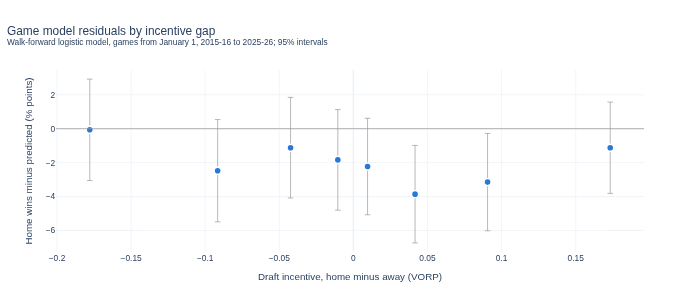

In [10]:
bins = incentive.residual_bins(with_inc, FIRST + 1, LAST, "diff_draft_incentive")
plot_residuals(bins, "Draft incentive, home minus away (VORP)").show()

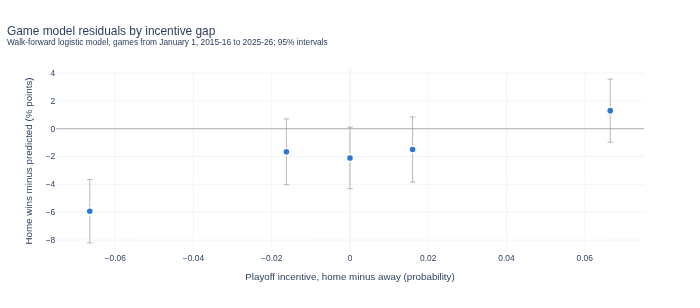

In [11]:
bins = incentive.residual_bins(with_inc, FIRST + 1, LAST, "diff_playoff_incentive", bins=5)
plot_residuals(bins, "Playoff incentive, home minus away (probability)").show()

## 2026-27

### 2027 first-round picks that changed hands

In [12]:
picks.TERMS_2027

,original,owner,terms
0,ATL,SAS,Unprotected
1,NYK,BRK,Unprotected
2,PHO,HOU,Unprotected
3,DAL,CHO,Top-2 protected
4,MIA,CHO,Top-14 protected
5,LAL,MEM,Top-4 protected
6,DEN,OKC,Top-5 protected
7,SAS,SAC / OKC,To SAC; SAC sends it to OKC unless 1-16
8,BRK,HOU / BRK,HOU takes the better of the HOU and BRK picks
9,CLE,MEM / UTA / PHO,"Of the CLE, MIN and UTA picks: MEM the best, U..."


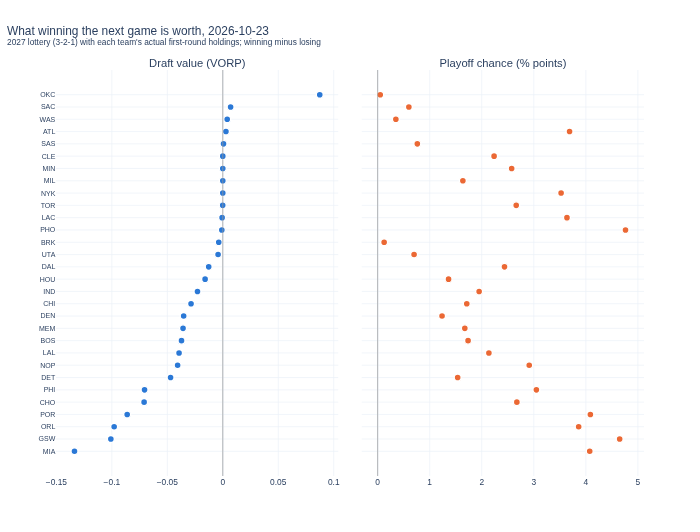

In [13]:
current = incentive.current(TODAY)
plot_current(current).show()

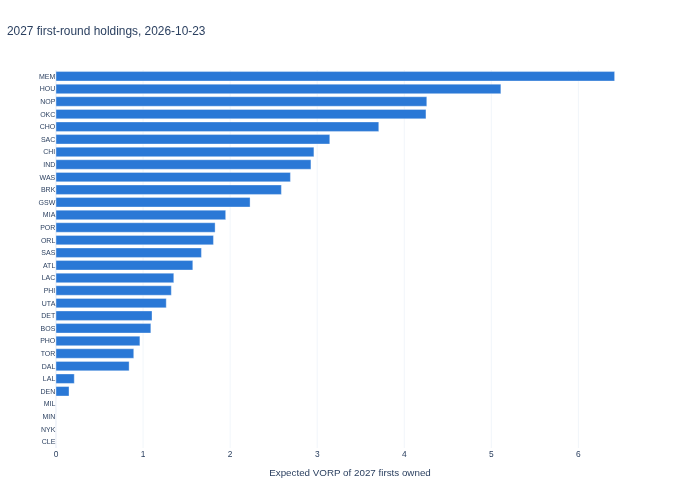

In [14]:
plot_holdings(current).show()

In [15]:
current.sort_values("draft_incentive")[
    ["team_id", "wins", "losses", "proj_wins", "playoffs", "exp_pick", "draft_value",
     "draft_incentive", "playoff_incentive", "next_game"]].round(3).reset_index(drop=True)

,team_id,wins,losses,proj_wins,playoffs,exp_pick,draft_value,draft_incentive,playoff_incentive,next_game
0,MIA,0.0,1.0,37.649,0.387,11.823,1.948,-0.134,0.041,2026-10-23
1,GSW,0.0,1.0,38.018,0.447,12.430,2.229,-0.101,0.046,2026-10-23
2,ORL,0.0,1.0,42.508,0.634,15.643,1.808,-0.098,0.039,2026-10-23
3,POR,1.0,0.0,41.727,0.646,15.308,1.827,-0.086,0.041,2026-10-23
4,CHO,1.0,0.0,46.950,0.826,19.608,3.707,-0.071,0.027,2026-10-23
5,PHI,2.0,0.0,47.520,0.848,20.093,1.324,-0.071,0.030,2026-10-24
6,DET,1.0,0.0,51.296,0.933,23.179,1.102,-0.047,0.015,2026-10-23
7,NOP,0.0,1.0,31.577,0.166,8.998,4.258,-0.041,0.029,2026-10-23
8,LAL,1.0,0.0,48.183,0.882,20.906,0.210,-0.039,0.021,2026-10-23
9,BOS,0.0,1.0,51.499,0.935,23.352,1.089,-0.037,0.017,2026-10-23
